<a href="https://colab.research.google.com/github/Kindlark/project-liceum/blob/main/notebooks/01_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Группа 1. Геометрия здания

X1 — Relative Compactness

Относительная компактность здания. Показывает, насколько форма здания компактна. Чем компактнее форма, тем меньше площадь внешней оболочки относительно объёма.

X2 — Surface Area

Общая площадь внешней поверхности здания, включая стены и крышу. Через внешнюю оболочку происходит теплообмен с окружающей средой.

X3 — Wall Area

Площадь наружных стен здания. Влияет на количество тепла, которое может передаваться через стены.

X4 — Roof Area

Площадь крыши здания. Через крышу также происходит теплообмен с внешней средой.

Группа 2. Оболочка и ориентация

X5 — Overall Height

Общая высота здания. В исходном датасете встречаются два значения: 3,5 и 7 метров.













X6 — Orientation

Ориентация здания относительно сторон света. В наборе используется числовое кодирование: 2, 3, 4 и 5.













X7 — Glazing Area

Доля остекления здания. Показывает, насколько большая часть площади приходится на окна. Влияет на теплопередачу и поступление солнечного тепла.













X8 — Glazing Area Distribution

Распределение остекления по фасадам. Показывает, как окна размещены на разных сторонах здания.


##Целевые переменные (Y1–Y2)
Это показатели, которые модель должна научиться предсказывать.

Y1 — Heating Load
Основная цель проекта
Тепловая нагрузка на отопление. Показывает, сколько тепловой энергии требуется зданию для поддержания заданных условий комфорта.

Y2 — Cooling Load

Нагрузка на охлаждение. Показывает, сколько энергии требуется для охлаждения здания и поддержания заданных условий комфорта.

Для проекта основной целевой переменной будет Y1 — Heating Load. Y2 можно использовать в качестве дополнительного направления исследования.

## КОД

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

sns.set_theme(style="whitegrid")

print("Библиотеки успешно загружены!")

Библиотеки успешно загружены!


In [3]:
# @title
description = {
    "Relative_Compactness": "Относительная компактность здания",
    "Surface_Area": "Общая площадь внешней поверхности",
    "Wall_Area": "Площадь наружных стен",
    "Roof_Area": "Площадь крыши",
    "Overall_Height": "Общая высота здания",
    "Orientation": "Ориентация здания",
    "Glazing_Area": "Доля остекления",
    "Glazing_Area_Distribution": "Распределение остекления",
    "Heating_Load": "Тепловая нагрузка на отопление",
    "Cooling_Load": "Нагрузка на охлаждение"
}

description_df = pd.DataFrame(
    list(description.items()),
    columns=["Название столбца", "Описание"]
)

display(description_df)

,Название столбца,Описание
0,Relative_Compactness,Относительная компактность здания
1,Surface_Area,Общая площадь внешней поверхности
2,Wall_Area,Площадь наружных стен
3,Roof_Area,Площадь крыши
4,Overall_Height,Общая высота здания
5,Orientation,Ориентация здания
6,Glazing_Area,Доля остекления
7,Glazing_Area_Distribution,Распределение остекления
8,Heating_Load,Тепловая нагрузка на отопление
9,Cooling_Load,Нагрузка на охлаждение


In [4]:
!pip install -q ucimlrepo openpyxl

from ucimlrepo import fetch_ucirepo
import pandas as pd

energy = fetch_ucirepo(id=242)

df = pd.concat(
    [energy.data.features, energy.data.targets],
    axis=1
)

print("Датасет успешно загружен!")
print("Размер:", df.shape)

display(df.head())

Датасет успешно загружен!
Размер: (768, 10)


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [5]:
df.columns = [
    "Relative_Compactness",
    "Surface_Area",
    "Wall_Area",
    "Roof_Area",
    "Overall_Height",
    "Orientation",
    "Glazing_Area",
    "Glazing_Area_Distribution",
    "Heating_Load",
    "Cooling_Load"
]

print(df.columns.tolist())

['Relative_Compactness', 'Surface_Area', 'Wall_Area', 'Roof_Area', 'Overall_Height', 'Orientation', 'Glazing_Area', 'Glazing_Area_Distribution', 'Heating_Load', 'Cooling_Load']


In [6]:
print("Размерность:", df.shape)
print("\nСтолбцы:")
print(df.columns.tolist())

print("\nПропуски:")
print(df.isnull().sum())

print("\nДубликаты:", df.duplicated().sum())

display(df.describe())

Размерность: (768, 10)

Столбцы:
['Relative_Compactness', 'Surface_Area', 'Wall_Area', 'Roof_Area', 'Overall_Height', 'Orientation', 'Glazing_Area', 'Glazing_Area_Distribution', 'Heating_Load', 'Cooling_Load']

Пропуски:
Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation                  0
Glazing_Area                 0
Glazing_Area_Distribution    0
Heating_Load                 0
Cooling_Load                 0
dtype: int64

Дубликаты: 0


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307201,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090196,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000


In [7]:
df.to_csv(
    "energy_efficiency_processed.csv",
    index=False
)

print("CSV успешно сохранён!")

CSV успешно сохранён!


In [8]:
df_check = pd.read_csv("energy_efficiency_processed.csv")

display(df_check.head())

print("Размер сохранённого файла:", df_check.shape)

,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


Размер сохранённого файла: (768, 10)


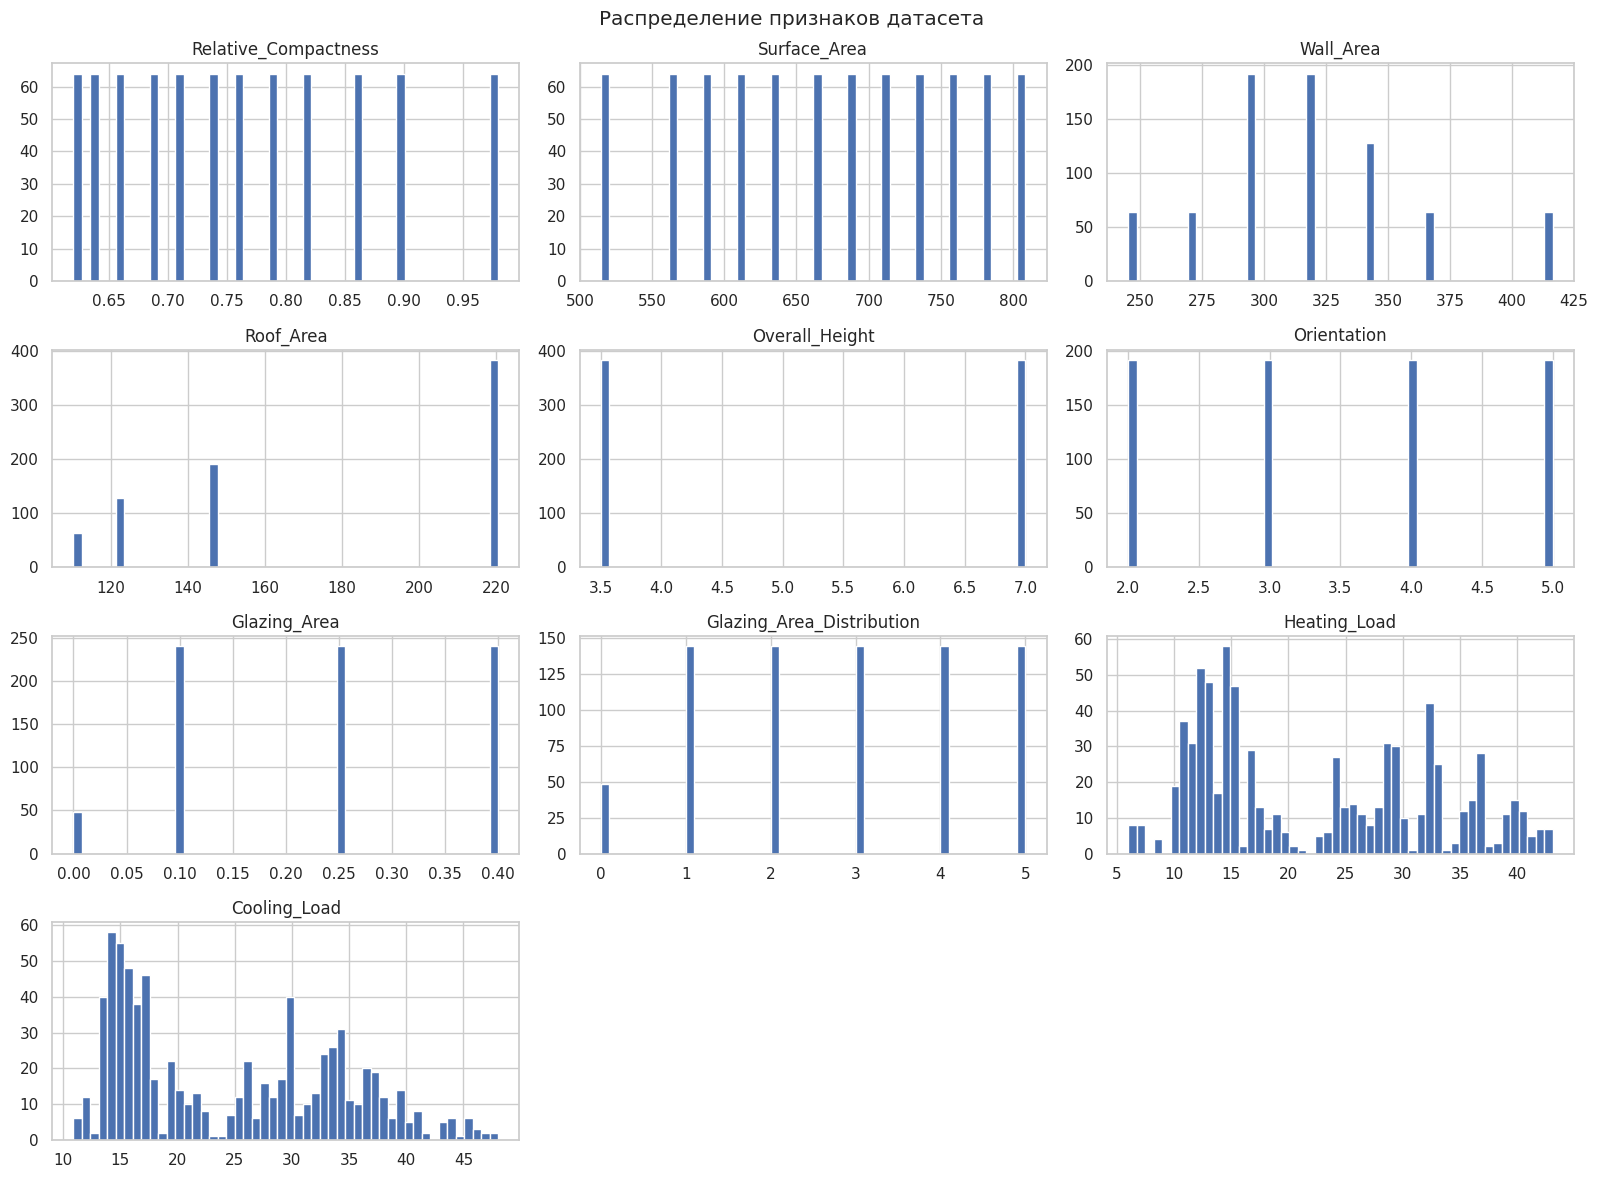

In [9]:
# @title
import matplotlib.pyplot as plt

df.hist(figsize=(16, 12), bins=50)

plt.suptitle("Распределение признаков датасета")
plt.tight_layout()
plt.show()

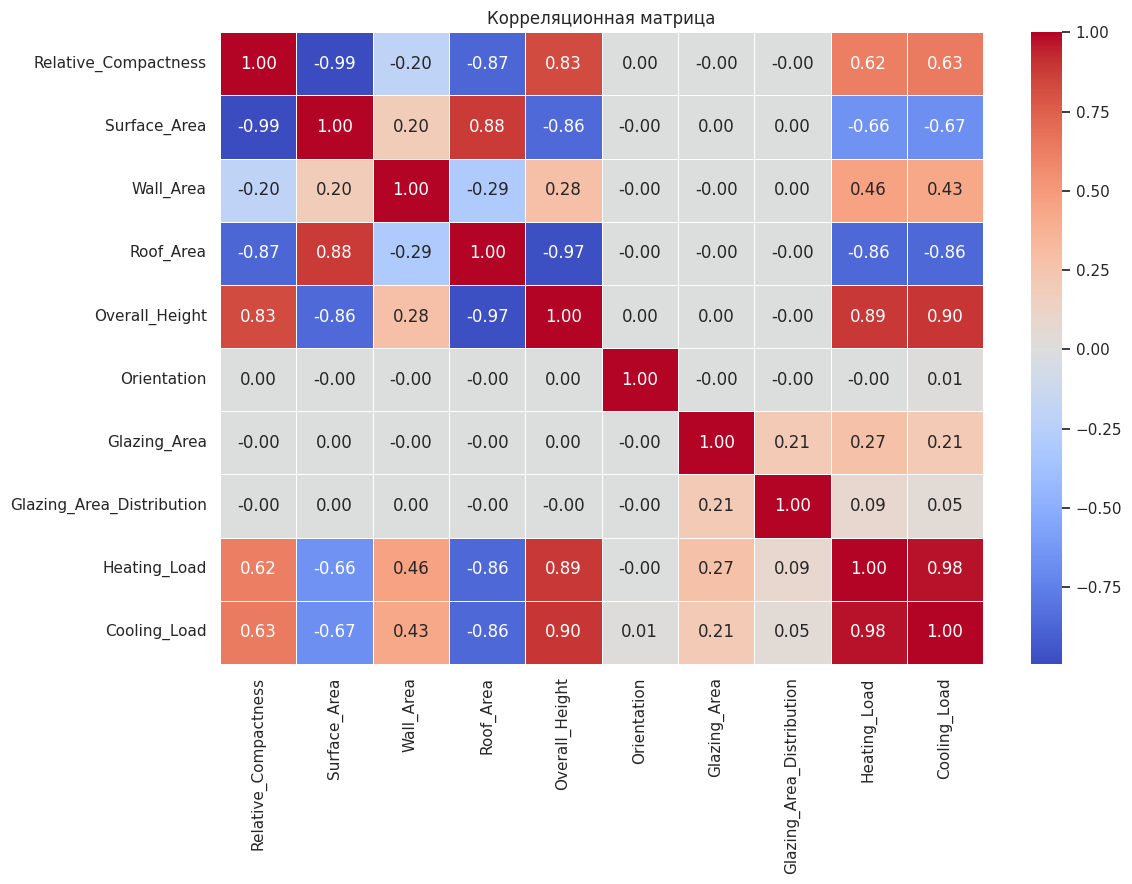

In [10]:
# @title
import seaborn as sns

plt.figure(figsize=(12, 9))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Корреляционная матрица")
plt.tight_layout()
plt.show()

In [11]:
# @title
description = {
    "Relative_Compactness": "Относительная компактность здания",
    "Surface_Area": "Общая площадь внешней поверхности",
    "Wall_Area": "Площадь наружных стен",
    "Roof_Area": "Площадь крыши",
    "Overall_Height": "Общая высота здания",
    "Orientation": "Ориентация здания",
    "Glazing_Area": "Доля остекления",
    "Glazing_Area_Distribution": "Распределение остекления",
    "Heating_Load": "Тепловая нагрузка на отопление",
    "Cooling_Load": "Нагрузка на охлаждение"
}

description_df = pd.DataFrame(
    list(description.items()),
    columns=["Название столбца", "Описание"]
)

display(description_df)

,Название столбца,Описание
0,Relative_Compactness,Относительная компактность здания
1,Surface_Area,Общая площадь внешней поверхности
2,Wall_Area,Площадь наружных стен
3,Roof_Area,Площадь крыши
4,Overall_Height,Общая высота здания
5,Orientation,Ориентация здания
6,Glazing_Area,Доля остекления
7,Glazing_Area_Distribution,Распределение остекления
8,Heating_Load,Тепловая нагрузка на отопление
9,Cooling_Load,Нагрузка на охлаждение


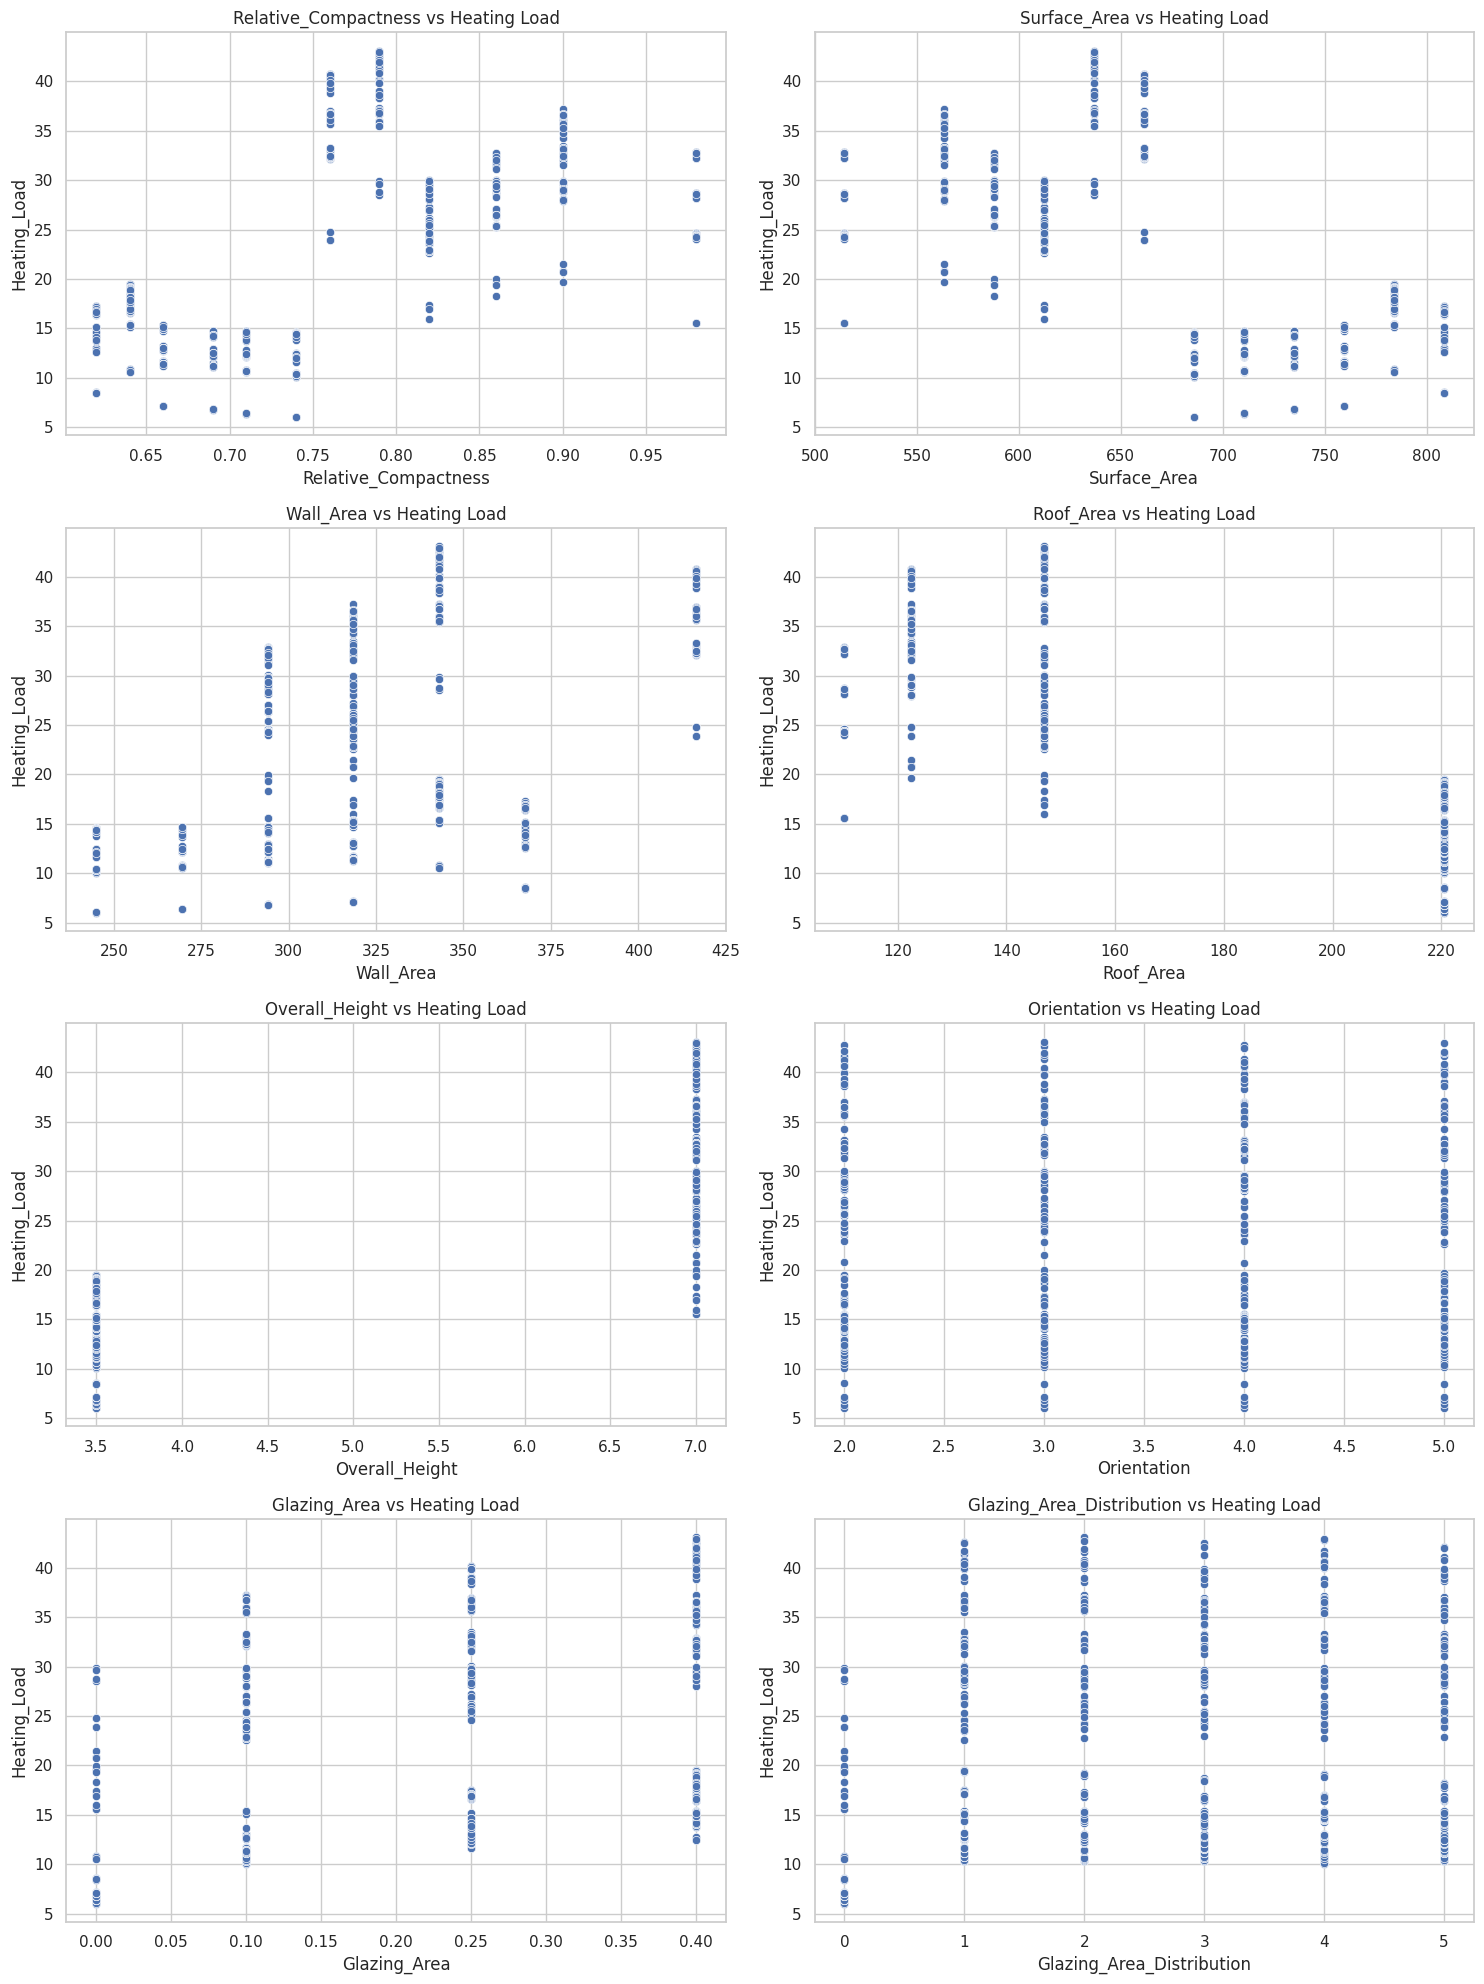

In [12]:
# @title
features = [
    "Relative_Compactness",
    "Surface_Area",
    "Wall_Area",
    "Roof_Area",
    "Overall_Height",
    "Orientation",
    "Glazing_Area",
    "Glazing_Area_Distribution"
]

fig, axes = plt.subplots(4, 2, figsize=(15, 20))

for feature, ax in zip(features, axes.flatten()):
    sns.scatterplot(
        data=df,
        x=feature,
        y="Heating_Load",
        ax=ax
    )

    ax.set_title(f"{feature} vs Heating Load")

plt.tight_layout()
plt.show()

In [13]:
features = [
    "Relative_Compactness",
    "Surface_Area",
    "Wall_Area",
    "Roof_Area",
    "Overall_Height",
    "Orientation",
    "Glazing_Area",
    "Glazing_Area_Distribution"
]

X = df[features]

y = df["Heating_Load"]

print("Количество признаков:", X.shape[1])
print("Количество наблюдений:", X.shape[0])

print("\nРазмер X:", X.shape)
print("Размер y:", y.shape)

Количество признаков: 8
Количество наблюдений: 768

Размер X: (768, 8)
Размер y: (768,)


In [18]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.1765,
    random_state=42
)

print("Обучающая выборка:", X_train.shape)
print("Валидационная выборка:", X_val.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (536, 8)
Валидационная выборка: (116, 8)
Тестовая выборка: (116, 8)


In [19]:
print("Общее количество наблюдений:", len(df))

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print("\nПроверка:")

total = len(X_train) + len(X_val) + len(X_test)

if total == len(df):
    print("Все данные успешно распределены!")
else:
    print("Ошибка при разделении данных!")

print("\nПропуски в обучающей выборке:", X_train.isnull().sum().sum())
print("Пропуски в валидационной выборке:", X_val.isnull().sum().sum())
print("Пропуски в тестовой выборке:", X_test.isnull().sum().sum())

Общее количество наблюдений: 768
Train: 536
Validation: 116
Test: 116

Проверка:
Все данные успешно распределены!

Пропуски в обучающей выборке: 0
Пропуски в валидационной выборке: 0
Пропуски в тестовой выборке: 0


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

scaling_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

print("Пайплайн масштабирования создан!")

Пайплайн масштабирования создан!


In [21]:
X_train_scaled = scaling_pipeline.fit_transform(X_train)

X_val_scaled = scaling_pipeline.transform(X_val)
X_test_scaled = scaling_pipeline.transform(X_test)

print("Масштабирование выполнено!")

print("\nРазмеры обработанных данных:")
print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Масштабирование выполнено!

Размеры обработанных данных:
Train: (536, 8)
Validation: (116, 8)
Test: (116, 8)


In [22]:
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=features
)

display(X_train_scaled_df.head())

print("\nСредние значения признаков:")
print(X_train_scaled_df.mean().round(2))

print("\nСтандартные отклонения:")
print(X_train_scaled_df.std().round(2))

,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution
0,-0.555173,0.487411,-1.142060,1.011543,-1.041923,-0.494350,1.224378,-1.157047
1,-1.030378,1.048039,0.025040,1.011543,-1.041923,1.320525,-0.996490,-0.516368
2,-0.079969,-0.073216,2.359241,-1.178005,0.959764,0.413087,0.113944,1.405669
3,-1.410541,1.608667,1.192141,1.011543,-1.041923,-1.401788,-0.996490,1.405669
4,-1.030378,1.048039,0.025040,1.011543,-1.041923,-0.494350,0.113944,1.405669



Средние значения признаков:
Relative_Compactness        -0.0
Surface_Area                 0.0
Wall_Area                    0.0
Roof_Area                    0.0
Overall_Height               0.0
Orientation                  0.0
Glazing_Area                 0.0
Glazing_Area_Distribution   -0.0
dtype: float64

Стандартные отклонения:
Relative_Compactness         1.0
Surface_Area                 1.0
Wall_Area                    1.0
Roof_Area                    1.0
Overall_Height               1.0
Orientation                  1.0
Glazing_Area                 1.0
Glazing_Area_Distribution    1.0
dtype: float64
